In [1]:
%env DYLD_FALLBACK_LIBRARY_PATH=/opt/homebrew/lib

from pathlib import Path

import pandas as pd

from thesis.run import _prepare_inventory

out_dir = Path("/Users/phillip/repositories/bachelor-thesis/data/dataset_v2/")
sources, context, boxes, counts = _prepare_inventory(out_dir)

df = pd.DataFrame(counts["boxes"]).T

env: DYLD_FALLBACK_LIBRARY_PATH=/opt/homebrew/lib


In [2]:
df.sort_values(by="box_contained_count", ascending=True).head(15)

,box_contained_count,content_pool_count,full_pool_count,rural_content_pool_count
eco_10_box_16,2,14,57,14
eco_10_box_01,3,4,11,4
eco_10_box_05,6,106,190,106
eco_10_box_10,6,211,316,211
eco_10_box_04,8,14,77,14
eco_10_box_13,8,13,25,13
eco_6_box_13,9,9,38,9
eco_13_box_02,12,29,106,29
eco_10_box_12,13,47,75,47
eco_6_box_07,13,49,117,49


In [3]:
df2 = pd.DataFrame(counts["retention_stages"])
df2

,count,fraction_of_input,fraction_of_previous,name
0,1377087,1.000000,1.000000,input
1,1377008,0.999943,0.999943,valid_polygon
2,1003510,0.728719,0.728761,min_area_m2
3,1000497,0.726531,0.996998,max_aspect_ratio


<Axes: >

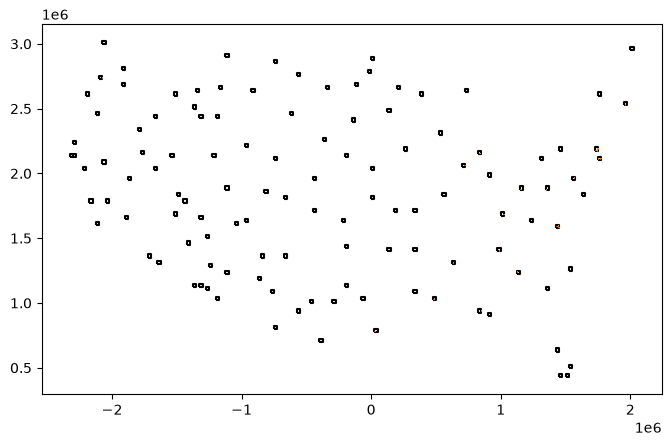

In [4]:
import geopandas as gpd

from thesis.config import load_config
from thesis.data.eligibility import CropReach, add_scene_geometries

imagery_config = load_config("imagery")

ax = boxes.geometry.boundary.plot(color="black", figsize=(8, 8))
sample = sources.sample(min(200, len(sources)), random_state=0)
sample.geometry.plot(ax=ax, color="tab:blue", markersize=2)

gsd = float(imagery_config["gsd_m"])
image_px = float(imagery_config["image_px"])
tip_row = int(imagery_config["tip_row"])
tip_col = int(imagery_config["tip_col"])
reach = CropReach(
    north_m=(tip_row + 0.5) * gsd,
    west_m=(tip_col + 0.5) * gsd,
    south_m=(image_px - tip_row - 0.5) * gsd,
    east_m=(image_px - tip_col - 0.5) * gsd,
)
sample_scenes = add_scene_geometries(
    sample,
    max_distance_m=imagery_config["scene_max_distance_m"],
    crop_reach=reach,
    slack_m=imagery_config["scene_slack_m"],
)
gpd.GeoSeries(sample_scenes["scene_geometry"], crs=sources.crs).boundary.plot(ax=ax, color="tab:orange", linewidth=0.5)

<Axes: >

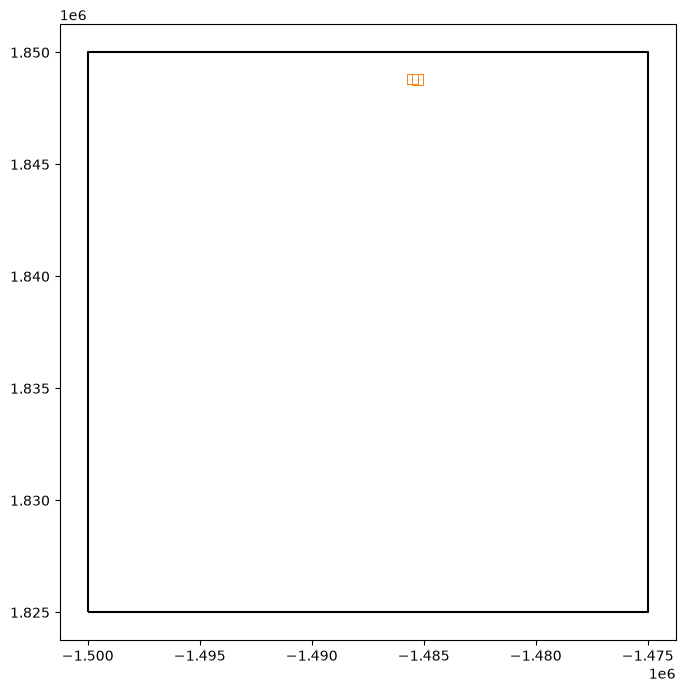

In [5]:
one_box_id = "eco_10_box_16"
box_geom = boxes.loc[boxes["box_id"] == one_box_id]
in_box = sources.loc[sources["box_id"] == one_box_id]

box_scenes = add_scene_geometries(
    in_box,
    max_distance_m=float(imagery_config["scene_max_distance_m"]),
    crop_reach=reach,
    slack_m=float(imagery_config["scene_slack_m"]),
)

ax = box_geom.boundary.plot(color="black", figsize=(8, 8))
in_box.geometry.plot(ax=ax, color="tab:blue", markersize=5)
gpd.GeoSeries(box_scenes["scene_geometry"], crs=box_scenes.crs).boundary.plot(ax=ax, color="tab:orange", linewidth=0.7)

In [6]:
from thesis.data import naip
from thesis.run import _geometry_to_crs, load_config

imagery_config = load_config("imagery")
box_geometries = boxes.set_index("box_id").geometry.to_dict()
one_box_id = next(iter(box_geometries))
box_wgs84 = _geometry_to_crs(box_geometries[one_box_id], "EPSG:5070", "EPSG:4326")
items = naip.search_items_for_geometry(box_wgs84, imagery_config)
len(items)

90

In [7]:
from thesis.run import _screen_box

marker_path = out_dir / "markers" / f"{one_box_id}.complete"
marker_path.parent.mkdir(parents=True, exist_ok=True)
_screen_box(
    one_box_id,
    marker_path,
    sources,
    context,
    box_geometries[one_box_id],
)

In [8]:
import json

json.loads((out_dir / "markers" / one_box_id / "counts.json").read_text())

{'box_id': 'eco_5_box_01',
 'eligible_count': 72,
 'footprint_provenance_mix': {'Microsoft ML Buildings': 0.05555555555555555,
  'OpenStreetMap': 0.9444444444444444},
 'imagery_dates': ['2021-07-24'],
 'imagery_seasons': ['summer'],
 'pre_naip_count': 72,
 'screened_count': 72,
 'tile_rejections': {}}

In [9]:
# full run

from thesis.run import run_screen

run_screen(out_dir)

In [10]:
from thesis.run import _audit_and_gate, _prepare_inventory

_, _, boxes, counts = _prepare_inventory(out_dir)
_audit_and_gate(out_dir, boxes, counts)

In [11]:
gate = json.loads((out_dir / "gate.json").read_text())

gate

{'ablation_sources': 100,
 'main_sources': 2000,
 'passed': True,
 'spill_count': 204,
 'spill_revisit_threshold': 100}

In [12]:
spill_info = pd.read_json(out_dir / "selection" / "spills.json")

selected = pd.read_parquet(out_dir / "selection" / "sources.parquet")
spilled = selected.loc[selected["box_id"].astype(str) != selected["quota_box_id"].astype(str)]
len(spilled)  # should be ~204, matching gate.json's spill_count

spilled.groupby(["quota_box_id", "box_id"]).size().sort_values(ascending=False)

quota_box_id   box_id       
eco_13_box_03  eco_13_box_04    5
eco_13_box_02  eco_13_box_01    4
eco_13_box_03  eco_13_box_01    4
eco_10_box_13  eco_10_box_03    3
               eco_10_box_07    3
                               ..
eco_10_box_04  eco_10_box_15    1
eco_5_box_01   eco_5_box_02     1
               eco_5_box_04     1
               eco_5_box_05     1
eco_9_box_10   eco_9_box_26     1
Length: 117, dtype: int64

In [13]:
spilled.groupby("quota_box_id").size().sort_values(ascending=False)

quota_box_id
eco_10_box_16    16
eco_10_box_14    15
eco_10_box_01    14
eco_10_box_10    14
eco_10_box_05    13
eco_6_box_13     13
eco_10_box_12    13
eco_10_box_13    13
eco_6_box_07     11
eco_6_box_05     11
eco_10_box_04    10
eco_13_box_03     9
eco_10_box_17     9
eco_10_box_19     9
eco_10_box_11     8
eco_13_box_02     7
eco_10_box_20     6
eco_5_box_01      4
eco_10_box_02     4
eco_6_box_06      3
eco_9_box_10      2
dtype: int64

In [14]:
coverage = pd.read_csv(out_dir / "audit" / "coverage.csv")

coverage.sort_values(by="coverage", ascending=True).head(10)

coverage.loc[coverage["scope"] == "global"].sort_values("coverage")

,scope,box_id,bin_id,available_sources,total_sources,coverage
1089,global,NaN,80,1756,2000,0.8780
0,global,NaN,-5,1838,2000,0.9190
968,global,NaN,40,1929,2000,0.9645
847,global,NaN,20,1997,2000,0.9985
121,global,NaN,-3,2000,2000,1.0000
242,global,NaN,-1,2000,2000,1.0000
363,global,NaN,1,2000,2000,1.0000
484,global,NaN,3,2000,2000,1.0000
605,global,NaN,5,2000,2000,1.0000
726,global,NaN,10,2000,2000,1.0000


In [15]:
smd = pd.read_csv(out_dir / "audit" / "availability_smd.csv")
smd.reindex(smd["smd"].abs().sort_values(ascending=False).index).head(10)

spacing_smd = pd.read_csv(out_dir / "audit" / "spacing_smd.csv")
spacing_smd.reindex(spacing_smd["smd"].abs().sort_values(ascending=False).index).head(10)

,covariate,smd
1,log_nearest_neighbor_distance,0.651295
2,neighbors_within_80m,-0.415864
6,footprint_area_m2_within_small,-0.184628
0,log_footprint_area,-0.106843
3,stratum_small,0.097027
8,footprint_area_m2_within_large,-0.064221
4,stratum_medium,-0.053628
7,footprint_area_m2_within_medium,-0.052362
5,stratum_large,-0.046948


In [16]:
spacing_smd = pd.read_csv(out_dir / "audit" / "spacing_smd.csv")
spacing_smd.reindex(spacing_smd["smd"].abs().sort_values(ascending=False).index).head(10)

# high SMD explained sperately. but important to note why

,covariate,smd
1,log_nearest_neighbor_distance,0.651295
2,neighbors_within_80m,-0.415864
6,footprint_area_m2_within_small,-0.184628
0,log_footprint_area,-0.106843
3,stratum_small,0.097027
8,footprint_area_m2_within_large,-0.064221
4,stratum_medium,-0.053628
7,footprint_area_m2_within_medium,-0.052362
5,stratum_large,-0.046948


In [17]:
# sanity check, manual
from thesis.run import run_sanity_render

run_sanity_render(out_dir, source_limit=200)

/Users/phillip/repositories/bachelor-thesis/.venv/lib/python3.12/site-packages/rasterio/__init__.py:377: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = writer(
/Users/phillip/repositories/bachelor-thesis/.venv/lib/python3.12/site-packages/rasterio/__init__.py:377: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = writer(
/Users/phillip/repositories/bachelor-thesis/.venv/lib/python3.12/site-packages/rasterio/__init__.py:377: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = writer(
/Users/phillip/repositories/bachelor-thesis/.venv/lib/python3.12/site-packages/rasterio/__init__.py:377: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = writer(
/Users/phillip/repositories/bachelor-thesis/.venv/lib/python3.12/site-pa